# 03 – Collaborative Filtering dựa trên láng giềng: ItemKNN

- **ItemKNN**: phim được cùng nhóm người dùng đánh giá giống nhau thì tương tự nhau.
- Độ tương đồng: **cosine** (rating thô) và **Pearson** (trừ trung bình trước khi cosine), có *shrinkage* để phạt cặp ít điểm chung.
- Dự đoán: $\hat r_{ui}=b_{ui}+\frac{\sum_j s_{ij}(r_{uj}-b_{uj})}{\sum_j |s_{ij}|}$ trên $k$ láng giềng (kNN-with-baseline).

Siêu tham số $k$ và loại similarity được **chọn trên tập validation** tách từ train, không dùng test, theo tiêu chí **NDCG@10** (chất lượng gợi ý Top-10).

---
### Bản chất từng mô hình

**Họ mô hình: memory-based CF (dựa trên bộ nhớ).** Không học tham số nào. "Huấn luyện" chỉ là tính sẵn ma trận độ tương đồng rồi ghi nhớ toàn bộ rating. Dự đoán = tham khảo cách user đã đánh giá những phim giống nhất. Mô hình chỉ dùng rating, hoàn toàn không biết nội dung phim.

**Bước chung: baseline + phần dư.** Trước tiên ước lượng $b_{ui} = \mu + b_u + b_i$:
- $\mu$: trung bình toàn cục.
- $b_u$: độ "khó tính" của user.
- $b_i$: độ "được ưa chuộng" của phim.

Hai bias được giải xen kẽ bằng bình phương tối thiểu có điều chuẩn (`fit_biases`, $\lambda_i = 25$, $\lambda_u = 10$). kNN chỉ dự đoán **phần dư** $r_{uj} - b_{uj}$. Nhờ vậy láng giềng mang thông tin "thích hơn/kém hơn mức bình thường", không bị lẫn với việc user chấm cao hay chấm thấp nói chung.

**Độ tương đồng $s$:**
- **Cosine:** góc giữa hai vector rating thô. Ô chưa chấm bằng 0.
- **Pearson:** trừ trung bình của chính vector đó, chỉ ở các ô đã chấm, rồi mới tính cosine. Cách này loại bỏ thói quen chấm điểm cao hoặc thấp.
- **Shrinkage:** nhân $s$ với $\frac{n}{n + 10}$, với $n$ là số phần tử chung. Hai phim chỉ có 1–2 người chấm chung dễ có $s$ cao một cách ngẫu nhiên, nên bị kéo về 0.
- Chỉ giữ láng giềng có $s > 0$ và giữ **top-k phim giống nhất cho mỗi phim**. Top-k này được chọn trên toàn bộ kho phim, nên số láng giềng user thực sự đã chấm (và dùng được để dự đoán) có thể ít hơn k.

**ItemKNN:** "bạn đã thích những phim giống phim này".
$$\hat r_{ui} = b_{ui} + \frac{\sum_{j \in N_k(i)} s_{ij}\,(r_{uj} - b_{uj})}{\sum_{j \in N_k(i)} |s_{ij}|}$$
Ma trận tương đồng có kích thước phim × phim (3706 × 3706). Mỗi phim có nhiều rating hơn mỗi user, nên độ tương đồng giữa các phim ổn định hơn độ tương đồng giữa các user; đây là lý do item-based kNN được dùng phổ biến trong thực tế (ví dụ Amazon). Gợi ý cũng **giải thích được**: "vì bạn đã thích phim X".

**Điểm mạnh:**
- Trực quan, dễ giải thích.
- Không cần huấn luyện lặp.
- Thêm rating mới chỉ cần cập nhật ma trận tương đồng.

**Điểm yếu:**
- Tốn bộ nhớ $O(n^2)$.
- Không khái quát được qua các phim không có láng giềng chung.
- Mẫu số $\sum |s|$ tự triệt tiêu độ lớn của $s$. Khi chỉ có 1 láng giềng yếu thì phần dư của láng giềng đó được dùng nguyên vẹn, nên phim ít rating dễ bị đẩy điểm quá cao và lọt lên đầu danh sách gợi ý. Trên validation, NDCG@10 cao nhất ở k = 5 (ít láng giềng nhưng sát nhất); dù vậy ItemKNN vẫn kém xa các mô hình implicit (xem notebook 08).

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import SELECT_METRIC, load_experiment, make_validation, run_model, save_metrics, validate

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
from src.models.knn_cf import ItemKNN
sub, val = make_validation(exp)
print(f"sub-train={len(sub):,}  validation={len(val):,}  | tiêu chí chọn: {SELECT_METRIC}")

sweep = []
for sim in ("cosine", "pearson"):
    for k in (5, 10, 20, 50, 100, 200):
        m = ItemKNN(k=k, similarity=sim).fit(sub, exp.user2idx, exp.item2idx, exp.movies)
        sweep.append(dict(Model="ItemKNN", similarity=sim, k=k, **validate(m, val)))
    print("done", sim)
sweep = pd.DataFrame(sweep); sweep.round(4)

sub-train=720,105  validation=80,088  | tiêu chí chọn: ValNDCG@10


done cosine


done pearson


,Model,similarity,k,ValNDCG@10
0,ItemKNN,cosine,5,0.0298
1,ItemKNN,cosine,10,0.0155
2,ItemKNN,cosine,20,0.0096
3,ItemKNN,cosine,50,0.0078
4,ItemKNN,cosine,100,0.0116
5,ItemKNN,cosine,200,0.0173
6,ItemKNN,pearson,5,0.0398
7,ItemKNN,pearson,10,0.0235
8,ItemKNN,pearson,20,0.0145
9,ItemKNN,pearson,50,0.0110


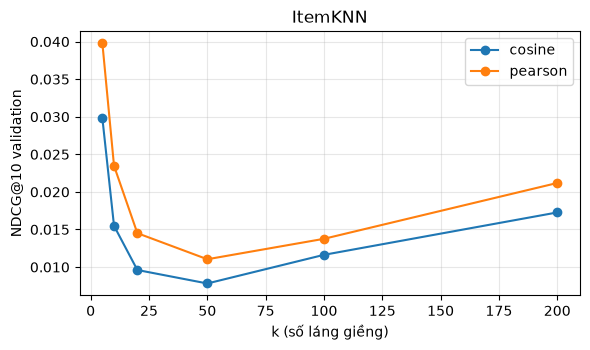

Model          ItemKNN
similarity     pearson
k                    5
ValNDCG@10    0.039813
Name: 6, dtype: object

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for sim, g in sweep.groupby("similarity"):
    ax.plot(g.k, g[SELECT_METRIC], marker="o", label=sim)
ax.set(title="ItemKNN", xlabel="k (số láng giềng)", ylabel="NDCG@10 validation"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "knn_k_sweep.png"); plt.show()
best = sweep.loc[sweep[SELECT_METRIC].idxmax()]; best

## Huấn luyện lại trên toàn bộ train với cấu hình tốt nhất và đánh giá trên test

In [4]:
res = pd.DataFrame([run_model(ItemKNN(k=int(best.k), similarity=best.similarity), exp)])
print("done", res.Model[0])

done ItemKNN(k=5,pearson)


In [5]:
res[['Model', 'Precision@10', 'Recall@10', 'NDCG@10', 'HitRate@10', 'Coverage@20', 'FitTime_s']].round(4)

,Model,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,FitTime_s
0,"ItemKNN(k=5,pearson)",0.0581,0.0487,0.0668,0.4161,0.8486,0.7429


In [6]:
save_metrics(res.assign(Family="Collaborative (kNN)"), "knn")

WindowsPath('D:/HỌC/kì 7/Machine Learning/machine_learning/outputs/metrics/knn.csv')